In [1]:
!pip install -q textstat nltk pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.1/177.1 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 47.1 MB/s eta 0:00:00


In [2]:
import re
import nltk
import pandas as pd
import textstat
import matplotlib.pyplot as plt

nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [3]:
# ============================================
# TEXT CLARITY & AMBIGUITY DETECTOR
# TSA PROJECT
# ============================================

import re
import textstat
import pandas as pd


# -----------------------------
# Ambiguous / vague words
# -----------------------------

VAGUE_WORDS = {
    "thing", "things",
    "stuff",
    "something",
    "anything",
    "someone",
    "somebody",
    "somewhere",
    "many",
    "several",
    "few",
    "various",
    "certain",
    "some",
    "soon",
    "later",
    "recently",
    "often",
    "usually",
    "sometimes",
    "probably",
    "maybe",
    "perhaps",
    "etc",
    "etc.",
    "good",
    "bad",
    "nice",
    "big",
    "small",
    "easy",
    "hard"
}


# -----------------------------
# Weak / uncertain expressions
# -----------------------------

UNCERTAIN_WORDS = {
    "maybe",
    "perhaps",
    "possibly",
    "probably",
    "might",
    "could",
    "seems",
    "seem",
    "apparently",
    "likely",
    "possibly"
}


# -----------------------------
# Sentence analysis
# -----------------------------

def analyze_text(text):

    text = text.strip()

    if not text:
        return {
            "clarity_score": 0,
            "ambiguity_score": 100,
            "classification": "No Text",
            "vague_words": [],
            "uncertain_words": [],
            "issues": ["Please enter some text."]
        }

    # Convert to lowercase
    lower_text = text.lower()

    # Extract words
    words = re.findall(r"\b[a-zA-Z]+\b", lower_text)

    # Find vague words
    vague_found = sorted(set(
        word for word in words
        if word in VAGUE_WORDS
    ))

    # Find uncertain words
    uncertain_found = sorted(set(
        word for word in words
        if word in UNCERTAIN_WORDS
    ))

    # Sentence count
    sentences = re.split(r"[.!?]+", text)
    sentences = [s.strip() for s in sentences if s.strip()]

    sentence_count = max(len(sentences), 1)

    # Word count
    word_count = len(words)

    # Average sentence length
    avg_sentence_length = word_count / sentence_count

    issues = []
    penalty = 0

    # -----------------------------
    # Vague words
    # -----------------------------

    if vague_found:
        penalty += min(len(vague_found) * 8, 30)
        issues.append(
            "Vague words detected: " +
            ", ".join(vague_found)
        )

    # -----------------------------
    # Uncertain language
    # -----------------------------

    if uncertain_found:
        penalty += min(len(uncertain_found) * 5, 20)
        issues.append(
            "Uncertain language detected: " +
            ", ".join(uncertain_found)
        )

    # -----------------------------
    # Long sentences
    # -----------------------------

    if avg_sentence_length > 30:
        penalty += 20
        issues.append(
            f"Sentences are very long (average {avg_sentence_length:.1f} words)."
        )

    elif avg_sentence_length > 20:
        penalty += 10
        issues.append(
            f"Some sentences may be long (average {avg_sentence_length:.1f} words)."
        )

    # -----------------------------
    # Very short text
    # -----------------------------

    if word_count < 5:
        penalty += 10
        issues.append("The text is too short to provide enough context.")

    # -----------------------------
    # Pronoun ambiguity
    # -----------------------------

    ambiguous_pronouns = re.findall(
        r"\b(it|this|that|they|them|these|those|he|she)\b",
        lower_text
    )

    if ambiguous_pronouns:
        penalty += min(len(set(ambiguous_pronouns)) * 4, 12)
        issues.append(
            "Potentially ambiguous references: " +
            ", ".join(sorted(set(ambiguous_pronouns)))
        )

    # -----------------------------
    # Repeated words
    # -----------------------------

    word_frequency = {}

    for word in words:
        word_frequency[word] = word_frequency.get(word, 0) + 1

    repeated_words = [
        word for word, count in word_frequency.items()
        if count >= 4 and len(word) > 3
    ]

    if repeated_words:
        penalty += 5
        issues.append(
            "Repeated words detected: " +
            ", ".join(repeated_words)
        )

    # -----------------------------
    # Readability
    # -----------------------------

    try:
        readability = textstat.flesch_reading_ease(text)
    except:
        readability = 50

    # Normalize readability
    readability_score = max(
        0,
        min(100, readability)
    )

    # Combine scores
    clarity_score = 100 - penalty

    # Add readability influence
    if readability_score < 30:
        clarity_score -= 10
        issues.append(
            "The text may be difficult to read."
        )

    elif readability_score < 50:
        clarity_score -= 5
        issues.append(
            "The text has moderate readability."
        )

    clarity_score = max(
        0,
        min(100, clarity_score)
    )

    ambiguity_score = 100 - clarity_score

    # -----------------------------
    # Classification
    # -----------------------------

    if clarity_score >= 80:
        classification = "Clear"

    elif clarity_score >= 60:
        classification = "Needs Improvement"

    else:
        classification = "Ambiguous"

    if not issues:
        issues.append("No major clarity problems detected.")

    # -----------------------------
    # Suggestions
    # -----------------------------

    suggestions = []

    if vague_found:
        suggestions.append(
            "Replace vague words with specific information."
        )

    if uncertain_found:
        suggestions.append(
            "Use precise statements instead of uncertain language."
        )

    if avg_sentence_length > 20:
        suggestions.append(
            "Break long sentences into shorter sentences."
        )

    if ambiguous_pronouns:
        suggestions.append(
            "Clearly identify what words such as 'it', 'this', or 'they' refer to."
        )

    if readability_score < 50:
        suggestions.append(
            "Use simpler words and clearer sentence structures."
        )

    if not suggestions:
        suggestions.append(
            "The text is reasonably clear. No major changes are required."
        )

    return {
        "clarity_score": round(clarity_score, 2),
        "ambiguity_score": round(ambiguity_score, 2),
        "classification": classification,
        "vague_words": vague_found,
        "uncertain_words": uncertain_found,
        "readability_score": round(readability_score, 2),
        "word_count": word_count,
        "sentence_count": sentence_count,
        "average_sentence_length": round(avg_sentence_length, 2),
        "issues": issues,
        "suggestions": suggestions
    }

In [4]:
text = """
I will send the thing later and maybe they can check it.
There are many issues that should probably be fixed soon.
"""

result = analyze_text(text)

print("====================================")
print(" TEXT CLARITY ANALYSIS")
print("====================================")

print("Clarity Score       :", result["clarity_score"])
print("Ambiguity Score     :", result["ambiguity_score"])
print("Classification      :", result["classification"])
print("Readability Score   :", result["readability_score"])
print("Word Count          :", result["word_count"])
print("Sentence Count      :", result["sentence_count"])
print("Average Sentence    :", result["average_sentence_length"])

print("\nVague Words:")
print(result["vague_words"])

print("\nUncertain Words:")
print(result["uncertain_words"])

print("\nIssues:")
for issue in result["issues"]:
    print("•", issue)

print("\nSuggestions:")
for suggestion in result["suggestions"]:
    print("•", suggestion)

 TEXT CLARITY ANALYSIS
Clarity Score       : 48
Ambiguity Score     : 52
Classification      : Ambiguous
Readability Score   : 88.0
Word Count          : 22
Sentence Count      : 2
Average Sentence    : 11.0

Vague Words:
['later', 'many', 'maybe', 'probably', 'soon', 'thing']

Uncertain Words:
['maybe', 'probably']

Issues:
• Vague words detected: later, many, maybe, probably, soon, thing
• Uncertain language detected: maybe, probably
• Potentially ambiguous references: it, that, they

Suggestions:
• Replace vague words with specific information.
• Use precise statements instead of uncertain language.
• Clearly identify what words such as 'it', 'this', or 'they' refer to.


In [5]:
from IPython.display import display, HTML
import ipywidgets as widgets

text_box = widgets.Textarea(
    value="",
    placeholder="Enter a sentence or paragraph here...",
    description="Text:",
    layout=widgets.Layout(
        width="90%",
        height="150px"
    )
)

button = widgets.Button(
    description="Analyze Text",
    button_style="primary"
)

output = widgets.Output()


def analyze_button_clicked(b):

    with output:
        output.clear_output()

        text = text_box.value

        if not text.strip():
            print("Please enter some text.")
            return

        result = analyze_text(text)

        print("======================================")
        print("       TEXT CLARITY ANALYZER")
        print("======================================")

        print(f"\nClarity Score     : {result['clarity_score']}/100")
        print(f"Ambiguity Score   : {result['ambiguity_score']}/100")
        print(f"Classification    : {result['classification']}")
        print(f"Readability      : {result['readability_score']}/100")

        print("\n🔍 Vague Words:")
        if result["vague_words"]:
            print(", ".join(result["vague_words"]))
        else:
            print("None")

        print("\n⚠️ Uncertain Words:")
        if result["uncertain_words"]:
            print(", ".join(result["uncertain_words"]))
        else:
            print("None")

        print("\n📌 Issues:")
        for issue in result["issues"]:
            print("•", issue)

        print("\n💡 Suggestions:")
        for suggestion in result["suggestions"]:
            print("•", suggestion)


button.on_click(analyze_button_clicked)

display(text_box)
display(button)
display(output)

Textarea(value='', description='Text:', layout=Layout(height='150px', width='90%'), placeholder='Enter a sente…

Button(button_style='primary', description='Analyze Text', style=ButtonStyle())

Output()

In [8]:
texts = [
    "Please submit the report by 5 PM on Friday.",
    "Please send me the thing soon.",
    "They should probably complete it later.",
    "The meeting will be conducted tomorrow at 10 AM.",
    "There are many things that need to be improved.",
    "The employee must submit the application before March 15."
]

results = []

for text in texts:

    result = analyze_text(text)

    results.append({
        "Text": text,
        "Clarity Score": result["clarity_score"],
        "Ambiguity Score": result["ambiguity_score"],
        "Classification": result["classification"],
        "Vague Words": ", ".join(result["vague_words"]),
        "Uncertain Words": ", ".join(result["uncertain_words"])
    })

df = pd.DataFrame(results)

display(df)

,Text,Clarity Score,Ambiguity Score,Classification,Vague Words,Uncertain Words
0,Please submit the report by 5 PM on Friday.,100,0,Clear,,
1,Please send me the thing soon.,84,16,Clear,"soon, thing",
2,They should probably complete it later.,71,29,Needs Improvement,"later, probably",probably
3,The meeting will be conducted tomorrow at 10 AM.,100,0,Clear,,
4,There are many things that need to be improved.,80,20,Clear,"many, things",
5,The employee must submit the application befor...,95,5,Clear,,


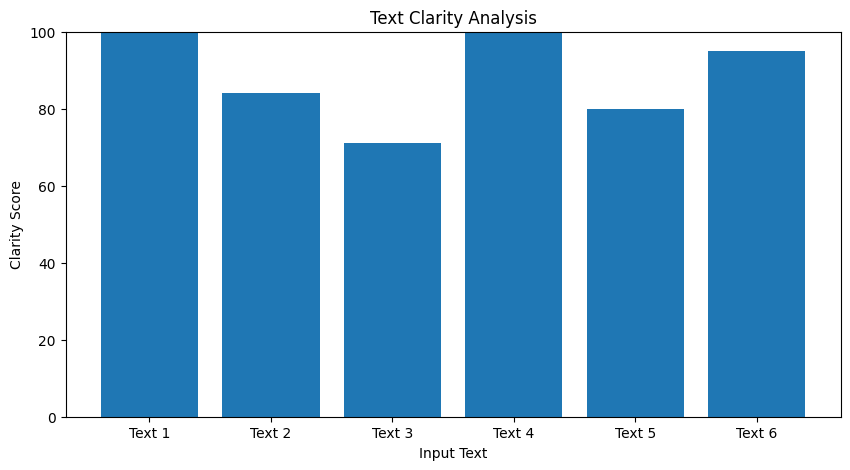

In [9]:
plt.figure(figsize=(10, 5))

plt.bar(
    range(len(df)),
    df["Clarity Score"]
)

plt.xticks(
    range(len(df)),
    [f"Text {i+1}" for i in range(len(df))]
)

plt.xlabel("Input Text")
plt.ylabel("Clarity Score")
plt.title("Text Clarity Analysis")

plt.ylim(0, 100)
plt.show()

In [10]:
from IPython.display import display, HTML
import ipywidgets as widgets

text_box = widgets.Textarea(
    value="",
    placeholder="Enter a sentence or paragraph here...",
    description="Text:",
    layout=widgets.Layout(
        width="90%",
        height="150px"
    )
)

button = widgets.Button(
    description="Analyze Text",
    button_style="primary"
)

output = widgets.Output()


def analyze_button_clicked(b):

    with output:
        output.clear_output()

        text = text_box.value

        if not text.strip():
            print("Please enter some text.")
            return

        result = analyze_text(text)

        print("======================================")
        print("       TEXT CLARITY ANALYZER")
        print("======================================")

        print(f"\nClarity Score     : {result['clarity_score']}/100")
        print(f"Ambiguity Score   : {result['ambiguity_score']}/100")
        print(f"Classification    : {result['classification']}")
        print(f"Readability      : {result['readability_score']}/100")

        print("\n🔍 Vague Words:")
        if result["vague_words"]:
            print(", ".join(result["vague_words"]))
        else:
            print("None")

        print("\n⚠️ Uncertain Words:")
        if result["uncertain_words"]:
            print(", ".join(result["uncertain_words"]))
        else:
            print("None")

        print("\n📌 Issues:")
        for issue in result["issues"]:
            print("•", issue)

        print("\n💡 Suggestions:")
        for suggestion in result["suggestions"]:
            print("•", suggestion)


button.on_click(analyze_button_clicked)

display(text_box)
display(button)
display(output)

Textarea(value='', description='Text:', layout=Layout(height='150px', width='90%'), placeholder='Enter a sente…

Button(button_style='primary', description='Analyze Text', style=ButtonStyle())

Output()